# BE1 . Data Science
### Identification des utilisateurs de Copilote à partir de leurs traces

**Bureau d'études réalisé par :**

* Hajar Zarguan
* Valentine Ponce
* Guillaume Sumian

### Objectif du projet

Ce projet vise à identifier les utilisateurs de Copilote à partir de leurs traces, en suivant trois étapes principales :

|  Étape | Description                                           |
| :----: | ----------------------------------------------------- |
| **01** | Analyse exploratoire des données                      |
| **02** | Construction et évaluation du modèle d'identification |
| **03** | Optimisation du modèle et analyse des performances    |


## Préparation : bibliothèques et lecture des données

In [ ]:
from pathlib import Path
import re
import math
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer 
from sklearn.feature_selection import chi2
from sklearn.preprocessing import normalize, OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


# Style
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({
    "figure.figsize": (9.5, 4.5), "figure.dpi": 70,
    "axes.spines.top": False, "axes.spines.right": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "right",
    "axes.edgecolor": "#bccffb", "grid.color": "#c6dbdd",
})
BLEU, ORANGE, GRIS = "#68baed", "#fa7e4d", "#a8a692"
COULEURS = ["#388cf2", "#f25313", "#1fc428", "#fabc2a", "#fc79bf", "#2cc72c", "#8271e3", "#eb6160"]
GRAINE = 42 #Sans graine fixe SI ON relance le notebook , ce dernier  changerait le découpage  d' apprentissage et la validation. L’exactitude passerait par exemple de 0,927 à 0,931, le t-SNE aurait une autre forme, et le meilleur réglage de l’optimisation pourrait même changer.

**Pour la  lecture :** nous avons constatés que les lignes n'ont pas toutes le même nombre de champs et donc un `pd.read_csv` classique ne convient pas. On lit donc le fichier **ligne par ligne**, sans le charger d'un bloc, et chaque ligne devient une session.

Un jeton est soit un marqueur temporel (`t5`, `t10`… : 5 s, 10 s… écoulées depuis le début de la session),
soit une action de la forme `Nom(écran)<configuration>$chaîne$1`, où tout ce qui suit le nom est facultatif
(le `1` final signale une modification de fiche).

In [42]:
def trouver(nom):
    """Cherche le fichier dans ../data (notebook lancé depuis scr/) ou data/, sans tenir compte des majuscules."""
    for dossier in [Path("../data"), Path("data")]:
        if dossier.is_dir():
            for f in dossier.iterdir():
                if f.name.lower() == nom.lower():
                    return f
    raise FileNotFoundError(f"{nom} introuvable dans ../data ni dans data")


def lire_sessions(fichier, avec_utilisateur):
    """Lit le fichier ligne par ligne. Renvoie la liste des sessions et le nombre de lignes vides."""
    sessions, lignes_vides = [], 0
    with open(fichier, encoding="utf-8-sig") as f:
        for ligne in f:
            ligne = ligne.strip()
            if not ligne:
                lignes_vides += 1
                continue
            champs = ligne.split(",")
            if avec_utilisateur:
                sessions.append({"util": champs[0], "navigateur": champs[1], "jetons": champs[2:]})
            else:
                sessions.append({"navigateur": champs[0], "jetons": champs[1:]})
    return sessions, lignes_vides


RE_TEMPS = re.compile(r"^t(\d+)$")
RE_ACTION = re.compile(r"^(?P<nom>[^(<$]*?)(?:\((?P<ecran>[^)]*)\))?(?:<(?P<conf>[^>]*)>)?(?:\$(?P<chaine>[^$]*)\$)?(?P<modif>1)?$")


def decrire_session(jetons):
    """Transforme la liste des jetons d'une session en quelques indicateurs simples."""
    types, actions, ecrans, configs, chaines = [], [], [], [], []
    fenetres = Counter()                 # nombre d'actions dans chaque fenêtre de 5 secondes
    t, n_marqueurs, n_vides, n_non_conformes = 0, 0, 0, 0
    for jeton in jetons:
        jeton = jeton.strip()
        if not jeton:
            n_vides += 1
            continue
        m = RE_TEMPS.match(jeton)
        if m:                            # marqueur temporel
            n_marqueurs += 1
            t = max(t, int(m.group(1)))
            continue
        m = RE_ACTION.match(jeton)       # action
        if m is None or not m["nom"].strip():
            n_non_conformes += 1
            nom = jeton
        else:
            nom = m["nom"].strip()
            if m["ecran"]:
                ecrans.append(m["ecran"])
            if m["conf"]:
                configs.append(m["conf"])
            if m["chaine"]:
                chaines.append(m["chaine"])
        types.append(nom.replace(" ", "_"))          # un symbole sans espace par action
        actions.append(jeton.replace(" ", "_"))
        fenetres[t] += 1

    n = len(types)
    n_fenetres = t // 5 + 1
    frequences = Counter(types)
    return {
        "n_actions": n,
        "n_marqueurs": n_marqueurs,
        "duree_s": t,                                            # durée estimée = dernier marqueur
        "cadence": n / max(t, 5),                                # actions par seconde
        "nb_types": len(frequences),
        "ratio_distinct": len(set(actions)) / max(n, 1),         # part d'actions différentes
        "entropie": -sum(c / n * math.log2(c / n) for c in frequences.values()) if n else 0.0,
        "nb_ecrans": len(set(ecrans)),
        "actions_par_fenetre": list(fenetres.values()) + [0] * (n_fenetres - len(fenetres)),
        "ecrans": ecrans, "configs": configs, "chaines": chaines,
        "doc_actions": " ".join(actions),                        # texte pour le TF-IDF
        "doc_types": " ".join(types),
        "n_champs_vides": n_vides, "n_non_conformes": n_non_conformes,
    }


fichier_train = trouver("train.csv")
train_brut, train_lignes_vides = lire_sessions(fichier_train, avec_utilisateur=True)
train = pd.DataFrame([{"util": s["util"], "navigateur": s["navigateur"], "empreinte": hash(tuple(s["jetons"])),
                       **decrire_session(s["jetons"])} for s in train_brut])
train["log_actions"] = np.log1p(train["n_actions"])
train["log_duree"] = np.log1p(train["duree_s"])
print(f"{fichier_train.name} : {len(train):,} sessions chargées (toutes les lignes du fichier).")
train[["util","navigateur"]].describe()

train.csv : 3,279 sessions chargées (toutes les lignes du fichier).


,util,navigateur
count,3279,3279
unique,247,4
top,skm,Firefox
freq,75,1466


---
# Section 1 . Exploration des données

## 1.1 Audit des données
Chaque ligne du tableau indique **ce qui est vérifié** , le **résultat** et **ce que ce résultat signifie** pour la suite.

In [ ]:
effectifs = train["util"].value_counts()
n_sessions = len(train)
non_conformes = int(train["n_non_conformes"].sum())
champs_vides = int(train["n_champs_vides"].sum())
sans_action = int((train["n_actions"] == 0).sum())
doublons = int(train.duplicated(["util", "navigateur", "empreinte"]).sum())
toutes_actions = Counter(a for doc in train["doc_actions"] for a in doc.split())


#L'ajout de la fonction filter action 
tous_types = Counter(a for doc in train["doc_types"] for a in doc.split()) 
#

def sens(valeur, si_zero, sinon):
    return si_zero if valeur == 0 else sinon


audit = pd.DataFrame([
    ("Nombre de sessions", f"{n_sessions:,}"),
    ("Nombre d'utilisateurs", f"{len(effectifs)}"),
    ("Sessions par utilisateur (min / médiane / max)", f"{effectifs.min()} / {effectifs.median():.0f} / {effectifs.max()}"),
    ("Navigateurs distincts", f"{train['navigateur'].nunique()}"),
    ("Lignes vides", f"{train_lignes_vides}"),
    ("Sessions sans aucune action", f"{sans_action}"),
    ("Valeurs manquantes (champs vides)", f"{champs_vides}"),
    ("Jetons qui ne respectent pas le format attendu", f"{non_conformes}"),
    ("Sessions en double (même utilisateur, même trace)", f"{doublons}"),
    ("Actions par session (min / médiane / max)",
     f"{train['n_actions'].min()} / {train['n_actions'].median():.0f} / {train['n_actions'].max():,}"),
    ("Types d'action distincts", f"{len(tous_types)}"),
    ("Jetons d'action distincts", f"{len(toutes_actions):,}"),
], columns=["Vérification", "Résultat"])

display(pd.DataFrame(list(tous_types.keys()), columns=["Actions distinctes"]))
with pd.option_context("display.max_colwidth", None):
    display(audit.style.hide(axis="index").set_properties(**{"text-align": "left"}))

,Actions distinctes
0,Création_d'un_écran
1,Affichage_d'une_dialogue
2,Exécution_d'un_bouton
3,Fermeture_d'une_dialogue
4,Double-clic
5,Lancement_d'une_stat
6,Affichage_d'un_toast
7,Lancement_d'une_action_générique
8,Filtrage_/_Tri
9,Saisie_dans_un_champ


Vérification,Résultat
Nombre de sessions,"3,279"
Nombre d'utilisateurs,247
Sessions par utilisateur (min / médiane / max),4 / 12 / 75
Navigateurs distincts,4
Lignes vides,0
Sessions sans aucune action,1
Valeurs manquantes (champs vides),0
Jetons qui ne respectent pas le format attendu,9
"Sessions en double (même utilisateur, même trace)",0
Actions par session (min / médiane / max),"0 / 340 / 11,977"


## 1.2 Utilisateurs et sessions
### Présence et activité des utilisateurs

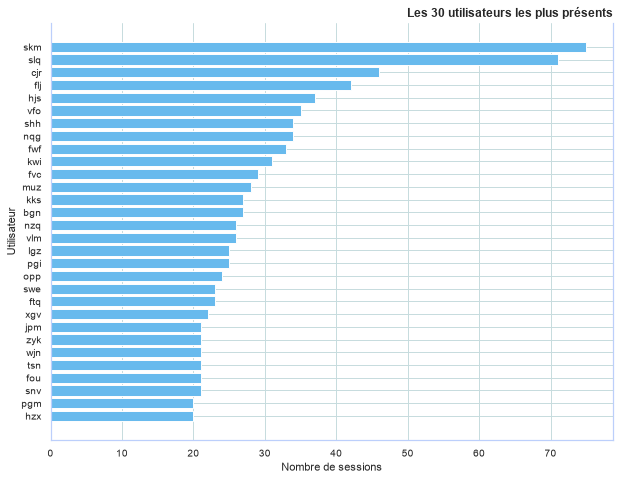

In [4]:
top30 = effectifs.head(30)
plt.figure(figsize=(9, 7))
plt.barh(top30.index[::-1], top30.values[::-1], color=BLEU)
plt.title("Les 30 utilisateurs les plus présents")
plt.xlabel("Nombre de sessions")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Chaque barre donne le nombre de sessions d'un utilisateur. Les utilisateurs les plus présents fournissent beaucoup
d'exemples au modèle : ce sont les plus faciles à apprendre.

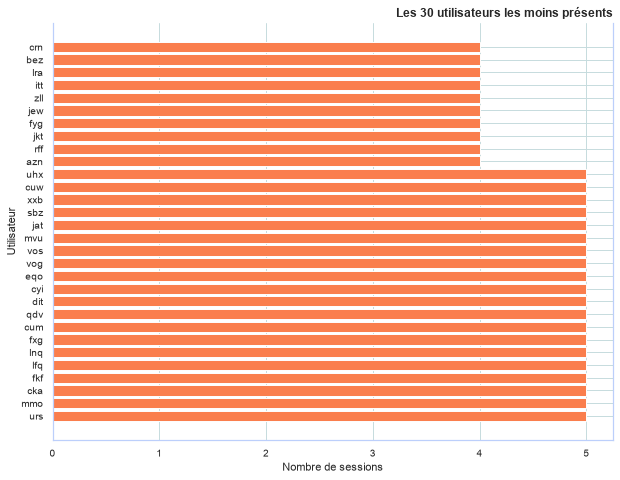

In [5]:
bas30 = effectifs.tail(30)
plt.figure(figsize=(9, 7))
plt.barh(bas30.index, bas30.values, color=ORANGE)
plt.title("Les 30 utilisateurs les moins présents")
plt.xlabel("Nombre de sessions")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

À l'opposé, ces utilisateurs n'ont que quelques sessions. Le modèle aura peu d'exemples pour apprendre leur façon de
travailler : c'est sur eux que l'on attend le plus d'erreurs.

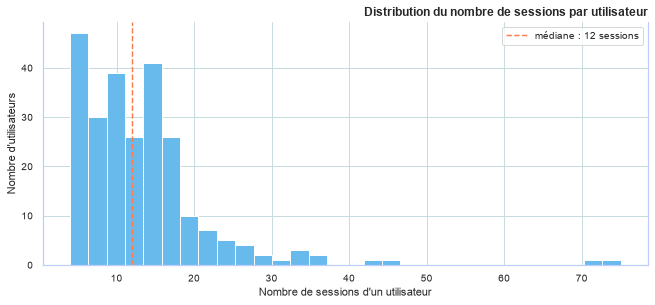

Un utilisateur a en médiane 12 sessions ; l'utilisateur le plus présent en a 75.


In [6]:
plt.figure()
plt.hist(effectifs.values, bins=30, color=BLEU, edgecolor="white")
plt.axvline(effectifs.median(), color=ORANGE, linestyle="--", label=f"médiane : {effectifs.median():.0f} sessions")
plt.title("Distribution du nombre de sessions par utilisateur")
plt.xlabel("Nombre de sessions d'un utilisateur")
plt.ylabel("Nombre d'utilisateurs")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Un utilisateur a en médiane {effectifs.median():.0f} sessions ; l'utilisateur le plus présent en a {effectifs.max()}.")

La plupart des utilisateurs ont peu de sessions et quelques-uns en ont beaucoup et donc les classes sont **déséquilibrées**.
On utilisera un découpage de chaque utilisateur garde sa proportion et on regardera aussi le F1 macro,
qui donne le même poids à chaque utilisateur.

### Navigateurs utilisés
On peut assumer que les utilisateurs semblent fidèles à leurs navigateurs

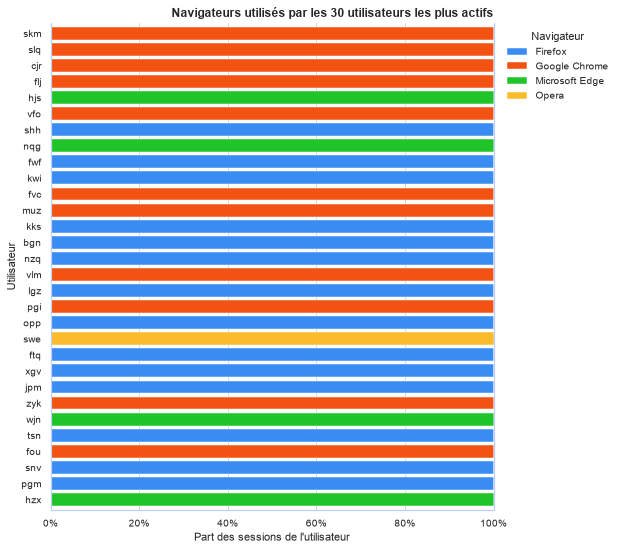

In [ ]:
navigateurs = train["navigateur"].value_counts().index
parts_nav = pd.crosstab(train["util"], train["navigateur"], normalize="index").loc[top30.index, navigateurs]
#Ajout du graphe navigateurs utiliser avec le calcul de la fidelitee des utilisateurs a leur nav 

#Abondonner ce graphe  
ax = parts_nav.plot(kind="barh", stacked=True, figsize=(9, 8), width=0.8,
                    color=COULEURS[:len(navigateurs)], edgecolor="white", linewidth=0.5)
ax.invert_yaxis()
ax.set_title("Navigateurs utilisés par les 30 utilisateurs les plus actifs")
ax.set_xlabel("Part des sessions de l'utilisateur")
ax.set_ylabel("Utilisateur")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="Navigateur", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()


### Longueur des sessions
La longueur d'une session est son nombre d'actions ... L'échelle est logarithmique, car les longueurs vont de quelques
actions à plusieurs milliers

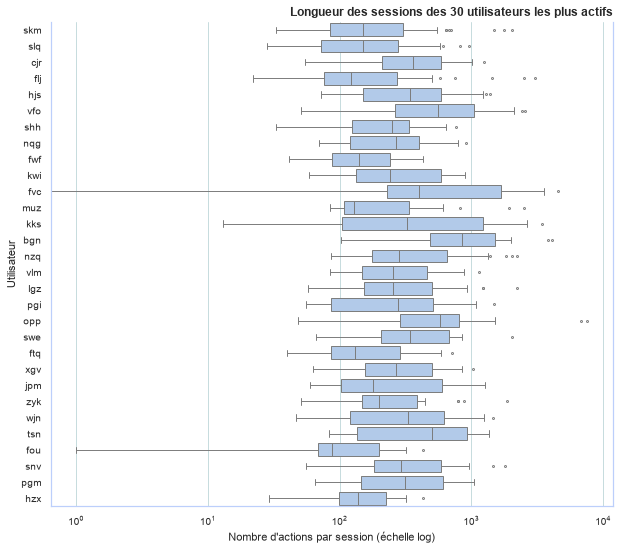

In [8]:
plt.figure(figsize=(9, 8))
sns.boxplot(data=train[train["util"].isin(top30.index)], y="util", x="n_actions", order=top30.index,
            color="#a9c9f2", fliersize=2, linewidth=1)
plt.xscale("log")
plt.title("Longueur des sessions des 30 utilisateurs les plus actifs")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Une boîte résume les sessions d'un utilisateur le trait central est la médiane, la boîte contient la moitié des
sessions, les points sont des sessions inhabituelles. Des boîtes placées à des hauteurs différentes indiquent que
certains utilisateurs font des sessions plus longues que d'autres.

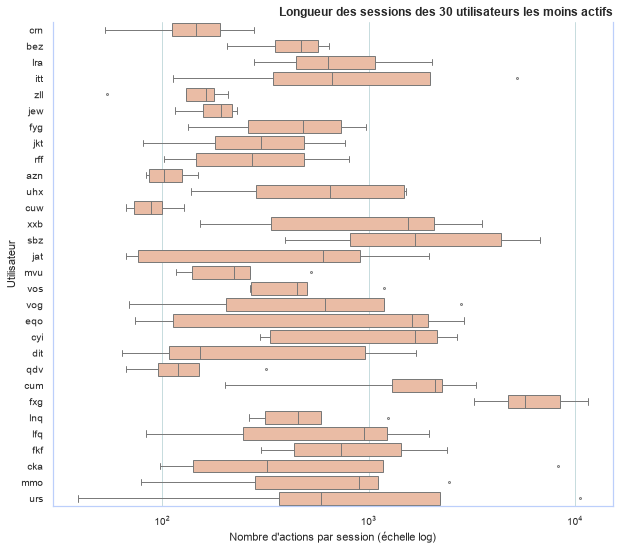

In [9]:
plt.figure(figsize=(9, 8))
sns.boxplot(data=train[train["util"].isin(bas30.index)], y="util", x="n_actions", order=bas30.index[::-1],
            color="#f5b899", fliersize=2, linewidth=1)
plt.xscale("log")
plt.title("Longueur des sessions des 30 utilisateurs les moins actifs")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Même lecture pour les utilisateurs les moins présents. Avec peu de sessions, une boîte est moins fiable : une seule
session longue suffit à la déplacer.

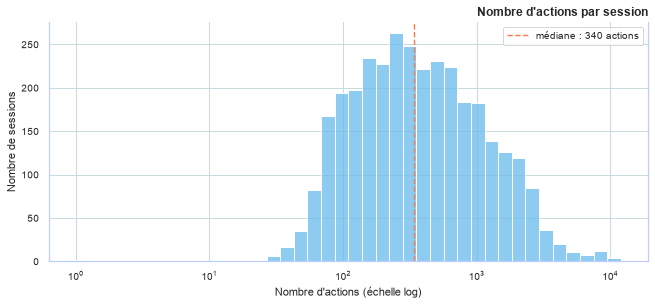

In [10]:
plt.figure()
sns.histplot(train["n_actions"].clip(lower=1), bins=40, log_scale=True, color=BLEU, edgecolor="white")
plt.axvline(train["n_actions"].median(), color=ORANGE, linestyle="--", label=f"médiane : {train['n_actions'].median():.0f} actions")
plt.title("Nombre d'actions par session")
plt.xlabel("Nombre d'actions (échelle log)")
plt.ylabel("Nombre de sessions")
plt.legend()
plt.tight_layout()
plt.show()

La plupart des sessions comptent quelques dizaines à quelques centaines d'actions, mais certaines en contiennent
des milliers Pour le modèle, on utilisera donc des **fréquences** d'actions normalisées plutôt que des comptages
bruts : sinon, les longues sessions écraseraient les courtes.

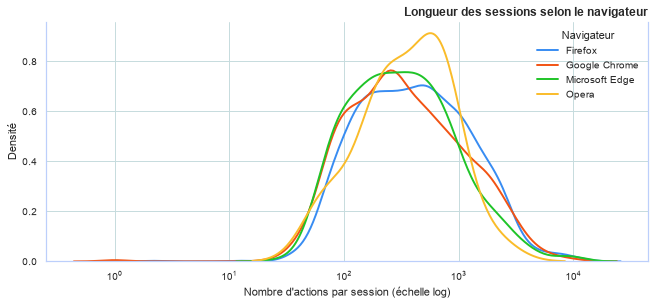

In [ ]:
plt.figure()
for couleur, nav in zip(COULEURS, navigateurs):
    sns.kdeplot(train.loc[train["navigateur"] == nav, "n_actions"].clip(lower=1), log_scale=True,
                color=couleur, linewidth=2, label=nav)
plt.title("Longueur des sessions selon le navigateur")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Densité")
plt.legend(title="Navigateur", frameon=False)
plt.tight_layout()
plt.show()

Chaque courbe montre comment se répartissent les longueurs de session pour un navigateur (plus la courbe est haute,
plus ces longueurs sont fréquentes). Si les courbes se superposent, la longueur ne dépend pas du navigateur.
#comment graphe utile ou pas 


## 1.3 Analyse des actions
### Tableau des types d'action
Le type d'une action est son nom, sans l'écran ni la configuration (par exemple « Exécution d'un bouton »).

In [ ]:
types_par_session = [set(doc.split()) for doc in train["doc_types"]]
utilisateurs_par_type = {}
for u, types in zip(train["util"], types_par_session):
    for ty in types:
        utilisateurs_par_type.setdefault(ty, set()).add(u)

total = sum(tous_types.values())
tableau_actions = pd.DataFrame([{
    "Type d'action": ty.replace("_", " "),
    "Occurrences": c,
    "Part des actions": f"{c / total:.1%}",
    "Sessions où il apparaît": f"{sum(ty in s for s in types_par_session) / n_sessions:.0%}",
    "Utilisateurs qui l'emploient": len(utilisateurs_par_type[ty]),
} for ty, c in tous_types.most_common(20)])
display(tableau_actions.style.hide(axis="index"))


#Changement de la representation du tableau au graphe

Type d'action,Occurrences,Part des actions,Sessions où il apparaît,Utilisateurs qui l'emploient
Exécution d'un bouton,510645,22.5%,100%,247
Saisie dans un champ,265633,11.7%,98%,247
Sélection d'un écran,206813,9.1%,92%,246
Fermeture d'une dialogue,171026,7.5%,98%,247
Affichage d'une dialogue,168928,7.4%,98%,247
Lancement d'une action générique,115283,5.1%,89%,246
Sélection d’un onglet,109209,4.8%,83%,245
Raccourci,82176,3.6%,59%,226
Création d'un écran,76929,3.4%,96%,246
Chainage,68194,3.0%,88%,245


Le tableau liste les 20 types d'action les plus fréquents. Un type présent dans presque toutes les sessions et
employé par tout le monde (comme un clic sur un bouton) distingue mal les utilisateurs ; un type plus rare, employé
par peu de personnes, est beaucoup plus révélateur de l'identité.

### Types d'action les plus liés aux utilisateurs : test du χ²

-Pour chaque type d'action, le test du χ² compare le nombre de fois où chaque utilisateur l'utilise avec ce que l'on observerait si tous les utilisateurs l'employaient dans les mêmes proportions.

-Plus le score est élevé, plus l'usage de ce type d'action dépend de l'utilisateur.


-Ces types d'action sont les plus utiles pour reconnaître quelqu'un.

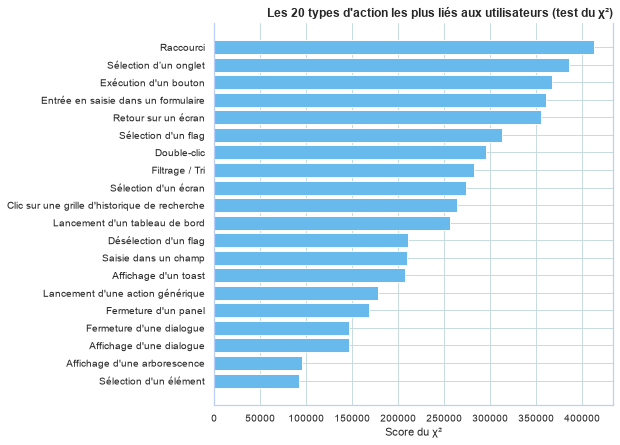

In [13]:
compteur_types = CountVectorizer(token_pattern=r"\S+", lowercase=False)
X_types = compteur_types.fit_transform(train["doc_types"])
scores_chi2, _ = chi2(X_types, train["util"])
noms_types = compteur_types.get_feature_names_out()
top20 = np.argsort(-np.nan_to_num(scores_chi2))[:20]

plt.figure(figsize=(9, 6.5))
plt.barh([noms_types[i].replace("_", " ") for i in top20[::-1]], scores_chi2[top20[::-1]], color=BLEU)
plt.title("Les 20 types d'action les plus liés aux utilisateurs (test du χ²)")
plt.xlabel("Score du χ²")
plt.tight_layout()
plt.show()

### Types d'action sur- et sous-représentés selon les utilisateurs

our chacun des 30 utilisateurs les plus actifs et chacun de ces 20 types d'action, on compare la part de ce type dans ses actions à la part moyenne sur tous les utilisateurs, en log base 2 :

**+1** = deux fois plus que la moyenne (orange), 

**−1** = deux fois moins (bleu), **0** = comme tout le monde (blanc).

 Chaque ligne est une sorte d'« empreinte » : deux utilisateurs dont les lignes diffèrent beaucoup seront
faciles à distinguer.

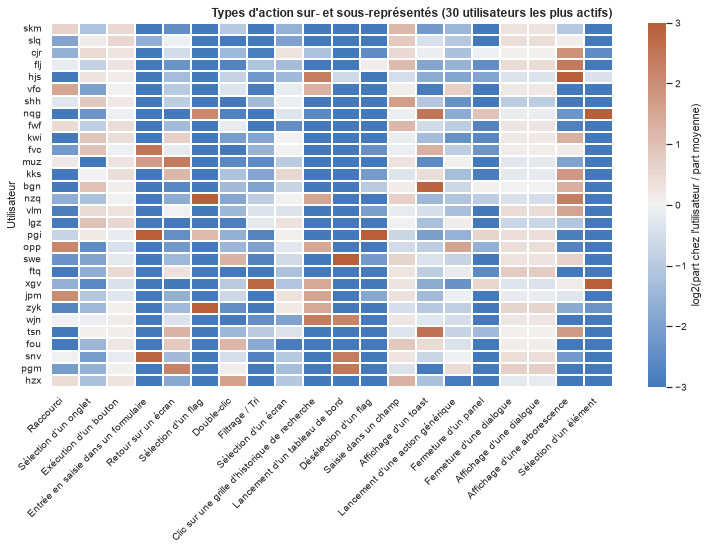

In [14]:
parts = pd.DataFrame(X_types[:, top20].toarray(), columns=[noms_types[i].replace("_", " ") for i in top20])
parts["util"] = train["util"].to_numpy()
comptes_u = parts.groupby("util").sum()
part_u = comptes_u.div(train.groupby("util")["n_actions"].sum(), axis=0)
part_moyenne = comptes_u.sum() / train["n_actions"].sum()
ecart = np.log2((part_u + 1e-4) / (part_moyenne + 1e-4)).loc[top30.index]

plt.figure(figsize=(11, 8))
sns.heatmap(ecart, cmap=sns.diverging_palette(250, 25, as_cmap=True), center=0, vmin=-3, vmax=3,
            linewidths=0.4, linecolor="white", cbar_kws={"label": "log2(part chez l'utilisateur / part moyenne)"})
plt.title("Types d'action sur- et sous-représentés (30 utilisateurs les plus actifs)")
plt.xlabel("")
plt.ylabel("Utilisateur")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Enchaînement des actions
 On compte les paires d'actions consécutives (« bigrammes ») : par exemple « Saisie dans un
champ → Exécution d'un bouton ».

Deux personnes peuvent faire les mêmes actions dans un ordre différent :
l'ordre est une information supplémentaire pour les reconnaître.

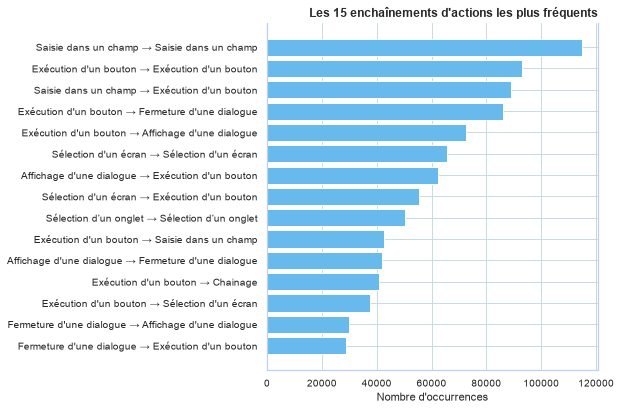

In [15]:
paires = Counter()
for doc in train["doc_types"]:
    ty = doc.split()
    paires.update(zip(ty, ty[1:]))

top_paires = paires.most_common(15)[::-1]
plt.figure(figsize=(9, 6))
plt.barh([f"{a.replace('_', ' ')} → {b.replace('_', ' ')}" for (a, b), _ in top_paires], [c for _, c in top_paires], color=BLEU)
plt.title("Les 15 enchaînements d'actions les plus fréquents")
plt.xlabel("Nombre d'occurrences")
plt.tight_layout()
plt.show()

Les enchaînements les plus fréquents sont souvent des répétitions (une saisie suivie d'une autre saisie) ou des
séquences logiques du logiciel (ouvrir une dialogue puis la fermer).

### Matrice de transition entre les 15 types d'action les plus fréquents
**Ce qui est calculé.** Chaque case donne la probabilité que l'action de la colonne suive l'action de la ligne :
on divise le nombre de transitions « ligne → colonne » par le nombre total de transitions qui partent de la ligne.
Chaque ligne fait donc 100 %. **Intérêt.** Si les utilisateurs ont des habitudes d'enchaînement différentes, les
paires d'actions consécutives aideront le modèle (on les utilisera comme variables en Section 2).

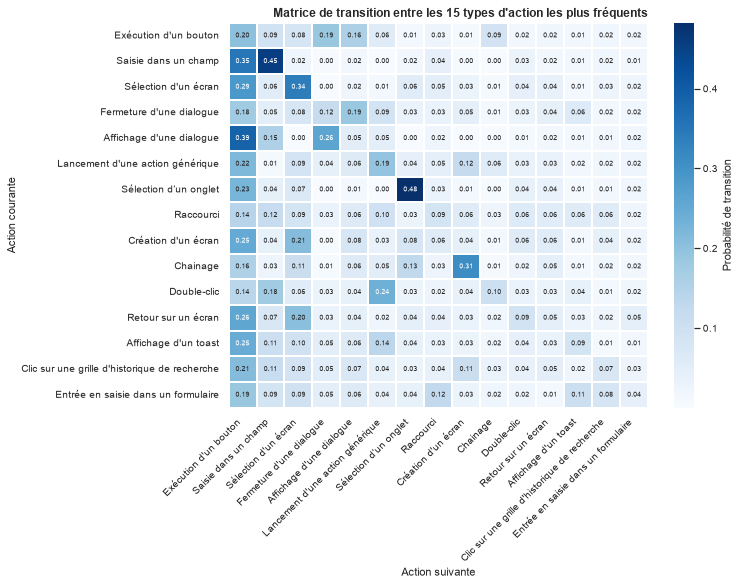

In [16]:
frequents = [ty for ty, _ in tous_types.most_common(15)]
transitions = pd.DataFrame(0.0, index=frequents, columns=frequents)
for (a, b), c in paires.items():
    if a in transitions.index and b in transitions.columns:
        transitions.loc[a, b] = c
transitions = transitions.div(transitions.sum(axis=1), axis=0)
etiquettes = [ty.replace("_", " ") for ty in frequents]

plt.figure(figsize=(11, 8.5))
sns.heatmap(transitions.set_axis(etiquettes).set_axis(etiquettes, axis=1), cmap="Blues", annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", cbar_kws={"label": "Probabilité de transition"})
plt.title("Matrice de transition entre les 15 types d'action les plus fréquents")
plt.xlabel("Action suivante")
plt.ylabel("Action courante")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Une case foncée signale un enchaînement très probable. La diagonale correspond aux répétitions d'une même action.

## 1.4 Comparaison des utilisateurs entre eux

**Sur quels critères ?** On compare les utilisateurs sur **les actions qu'ils utilisent et leur fréquence**, en
prenant le jeton d'action complet (type + écran + configuration + chaîne), qui est la description la plus précise.

**Comment est-ce calculé ?**
1. Chaque session est transformée en vecteur **TF-IDF** : une case par jeton d'action. La valeur augmente quand le
   jeton est fréquent dans la session (TF) et diminue quand il est présent dans presque toutes les sessions (IDF), car
   un jeton que tout le monde utilise n'aide pas à distinguer les personnes.
2. Le **profil** d'un utilisateur est la moyenne des vecteurs de ses sessions.
3. On compare deux profils avec la **similarité cosinus** : 1 si les deux utilisateurs utilisent les mêmes actions
   dans les mêmes proportions, 0 s'ils n'ont aucune action en commun.

**Comment interpréter ?** Une similarité faible entre deux utilisateurs signifie qu'ils travaillent différemment
(autres écrans, autres modules) : le modèle les séparera facilement. Une similarité forte signale deux personnes au
comportement proche (même poste, mêmes tâches) : ce sont elles que le modèle risque de confondre.

**Intérêt pour la modélisation.** Si la plupart des paires sont peu similaires, une représentation TF-IDF des actions
est un bon point de départ pour le modèle d'identification.

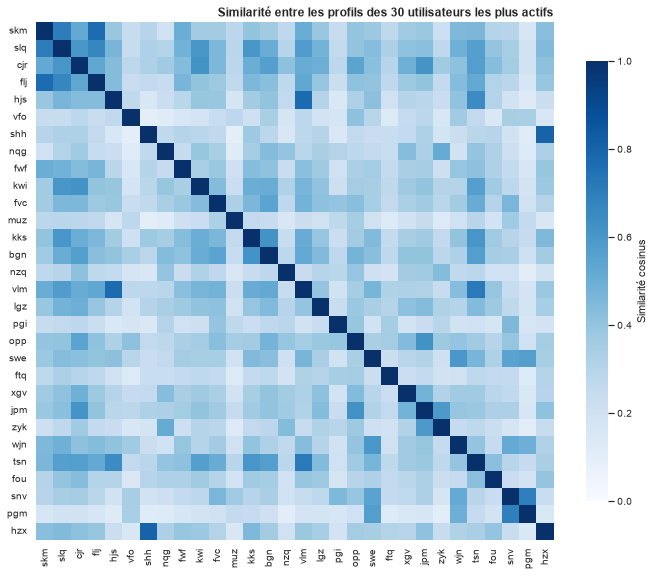

In [17]:
tfidf_eda = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True, min_df=2)
X_eda = tfidf_eda.fit_transform(train["doc_actions"])

utilisateurs = effectifs.index
profils = np.vstack([np.asarray(X_eda[(train["util"] == u).to_numpy()].mean(axis=0)) for u in utilisateurs])
profils = normalize(profils)
similarites = pd.DataFrame(profils @ profils.T, index=utilisateurs, columns=utilisateurs)

plt.figure(figsize=(10, 8.5))
sns.heatmap(similarites.loc[top30.index, top30.index], cmap="Blues", vmin=0, vmax=1, square=True,
            cbar_kws={"label": "Similarité cosinus", "shrink": 0.8})
plt.title("Similarité entre les profils des 30 utilisateurs les plus actifs")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

La diagonale vaut 1 (chaque utilisateur est identique à lui-même). Hors de la diagonale, une case claire indique deux
utilisateurs très différents, une case foncée deux utilisateurs proches.

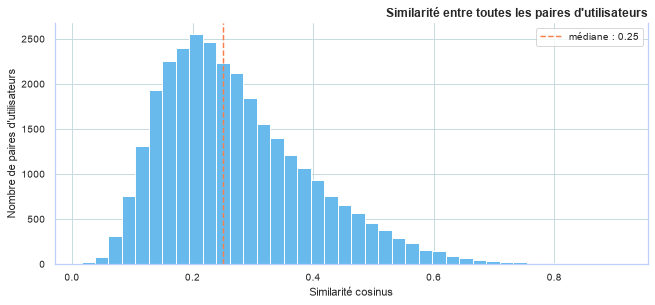

Paires d'utilisateurs les plus proches (risque de confusion) :
  txk et ptb : similarité 0.91
  ptb et sdx : similarité 0.91
  txk et sdx : similarité 0.89
  wuy et nkb : similarité 0.88
  wwk et wcf : similarité 0.88


In [18]:
haut = np.triu_indices(len(utilisateurs), k=1)
valeurs = similarites.to_numpy()[haut]

plt.figure()
plt.hist(valeurs, bins=40, color=BLEU, edgecolor="white")
plt.axvline(np.median(valeurs), color=ORANGE, linestyle="--", label=f"médiane : {np.median(valeurs):.2f}")
plt.title("Similarité entre toutes les paires d'utilisateurs")
plt.xlabel("Similarité cosinus")
plt.ylabel("Nombre de paires d'utilisateurs")
plt.legend()
plt.tight_layout()
plt.show()

plus_proches = np.argsort(-valeurs)[:5]
print("Paires d'utilisateurs les plus proches (risque de confusion) :")
for i in plus_proches:
    print(f"  {utilisateurs[haut[0][i]]} et {utilisateurs[haut[1][i]]} : similarité {valeurs[i]:.2f}")

Si l'essentiel des paires se trouve à gauche (similarité faible), les utilisateurs ont des façons de travailler bien
distinctes. Les quelques paires très proches listées ci-dessus sont à surveiller lors de l'évaluation du modèle.

## 1.5 Analyse temporelle
Les marqueurs `t5`, `t10`, `t15`… indiquent que 5, 10, 15 secondes se sont écoulées depuis le début de la session.
Ce ne sont pas des horodatages précis : la durée n'est connue qu'à 5 secondes près.

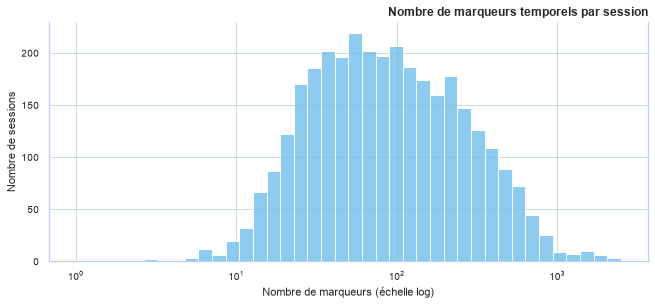

In [ ]:
# A SUPPRIMER 
plt.figure()
sns.histplot(train["n_marqueurs"].clip(lower=1), bins=40, log_scale=True, color=BLEU, edgecolor="white")
plt.title("Nombre de marqueurs temporels par session")
plt.xlabel("Nombre de marqueurs (échelle log)")
plt.ylabel("Nombre de sessions")
plt.tight_layout()
plt.show()

Un marqueur apparaît environ toutes les 5 secondes : ce nombre mesure donc la durée de la session, en « tranches »
de 5 secondes.

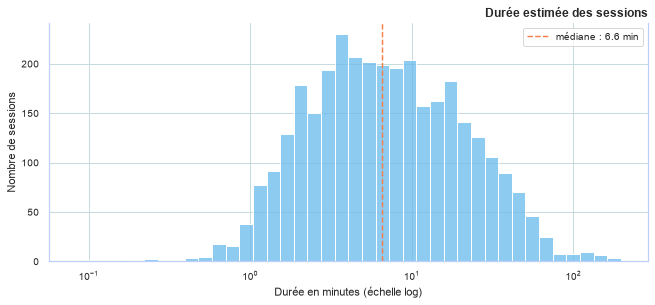

In [20]:
duree_min = train["duree_s"] / 60
plt.figure()
sns.histplot(duree_min.clip(lower=5 / 60), bins=40, log_scale=True, color=BLEU, edgecolor="white")
plt.axvline(duree_min.median(), color=ORANGE, linestyle="--", label=f"médiane : {duree_min.median():.1f} min")
plt.title("Durée estimée des sessions")
plt.xlabel("Durée en minutes (échelle log)")
plt.ylabel("Nombre de sessions")
plt.legend()
plt.tight_layout()
plt.show()

La durée estimée est la valeur du dernier marqueur. Les sessions vont de quelques secondes à plus d'une heure ;
comme pour le nombre d'actions, on passera cette variable au logarithme avant de l'utiliser.

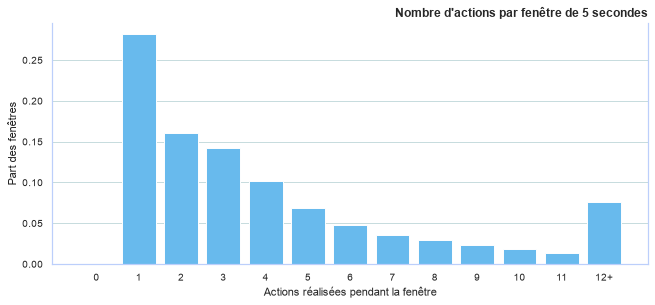

0% des fenêtres de 5 secondes ne contiennent aucune action (pause).


In [21]:
toutes_fenetres = Counter()
for liste in train["actions_par_fenetre"]:
    toutes_fenetres.update(min(c, 12) for c in liste)         # 12 et plus regroupés
fenetres = pd.Series(toutes_fenetres).sort_index()

plt.figure()
plt.bar([str(i) if i < 12 else "12+" for i in fenetres.index], fenetres.values / fenetres.sum(), color=BLEU)
plt.title("Nombre d'actions par fenêtre de 5 secondes")
plt.xlabel("Actions réalisées pendant la fenêtre")
plt.ylabel("Part des fenêtres")
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"{fenetres.get(0, 0) / fenetres.sum():.0%} des fenêtres de 5 secondes ne contiennent aucune action (pause).")

Ce graphique décrit le **rythme** de travail : beaucoup de fenêtres vides signalent des pauses (lecture, réflexion),
des fenêtres à 10 actions ou plus un travail rapide (saisies enchaînées). Ce rythme est résumé dans la variable
`cadence` (actions par seconde), utilisée par le modèle.

## 1.6 Composants logiciels
Les parties entre parenthèses, chevrons et dollars indiquent **où** l'utilisateur travaille dans le logiciel.
Chaque personne n'utilise qu'une partie du logiciel, selon son métier : ces composants sont donc de bons indices
d'identité.

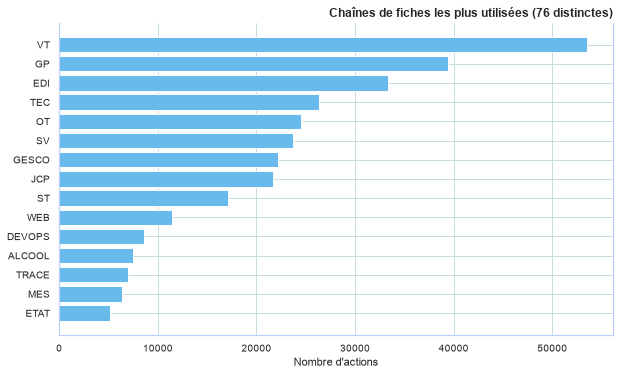

In [22]:
def barres_top(compteur, titre, xlabel, n=15, couleur=BLEU):
    """Diagramme en barres horizontales des n valeurs les plus fréquentes."""
    top = compteur.most_common(n)[::-1]
    etiquettes = [v if len(v) <= 45 else "…" + v[-44:] for v, _ in top]   # garde la fin des noms longs
    plt.figure(figsize=(9, 5.5))
    plt.barh([e.replace("$", r"\$") for e in etiquettes], [c for _, c in top], color=couleur)
    plt.title(titre)
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()


chaines = Counter(c for liste in train["chaines"] for c in liste)
barres_top(chaines, f"Chaînes de fiches les plus utilisées ({len(chaines)} distinctes)", "Nombre d'actions")

Les **chaînes de fiches** (entre dollars, par exemple `$EDI$`) indiquent le circuit de documents sur lequel
l'utilisateur travaille. Une chaîne propre à un service est un indice fort sur le métier, donc sur la personne.

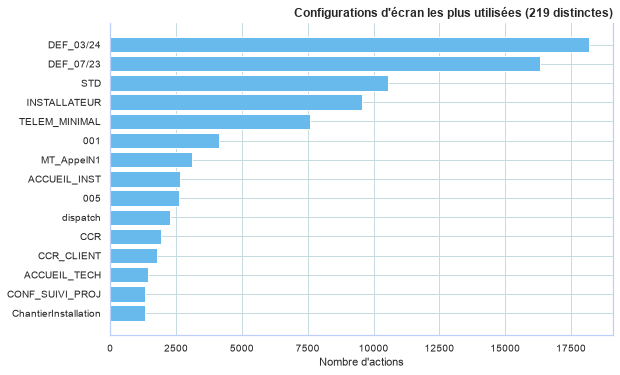

In [23]:
configs = Counter(c for liste in train["configs"] for c in liste)
barres_top(configs, f"Configurations d'écran les plus utilisées ({len(configs)} distinctes)", "Nombre d'actions")

Les **configurations d'écran** (entre chevrons) sont des réglages d'affichage. Certaines semblent personnelles ou
propres à une équipe : un utilisateur qui utilise toujours la même configuration se trahit par ce simple détail.

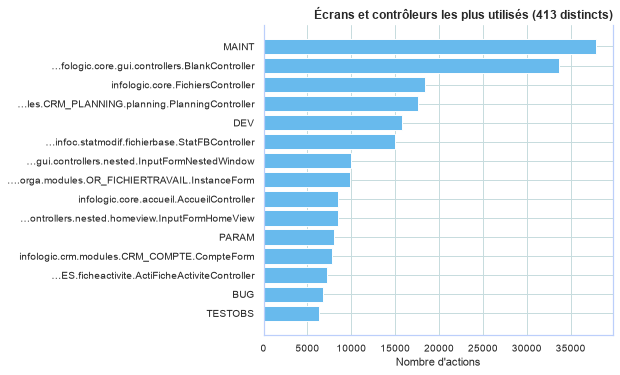

In [24]:
ecrans = Counter(e for liste in train["ecrans"] for e in liste)
barres_top(ecrans, f"Écrans et contrôleurs les plus utilisés ({len(ecrans)} distincts)", "Nombre d'actions")

Les **écrans et contrôleurs** (entre parenthèses) sont les pages du logiciel ouvertes par l'utilisateur. Leur nom
complet est long : on n'affiche que la fin, la plus parlante.

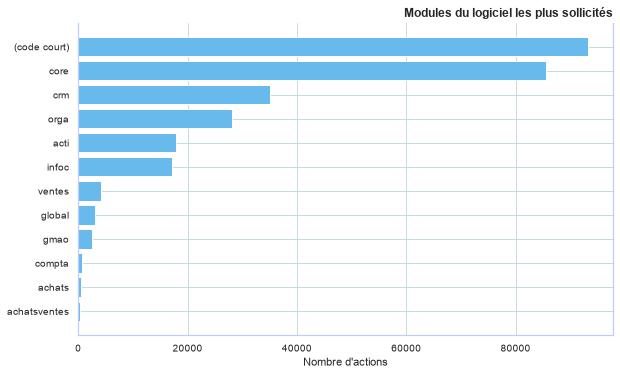

In [25]:
def module(ecran):
    """Module du logiciel, lu dans le nom de l'écran : infologic.crm.modules... -> crm."""
    morceaux = ecran.split(".")
    if "infologic" in morceaux[:-1]:
        return morceaux[morceaux.index("infologic") + 1]
    return "(code court)"


modules = Counter()
for e, c in ecrans.items():
    modules[module(e)] += c
barres_top(modules, "Modules du logiciel les plus sollicités", "Nombre d'actions", n=12)